Question 15

Running Q15 on: cpu


/usr/local/lib64/python3.9/site-packages/torch/hub.py:330: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to {calling_fn}(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  warnings.warn(


Downloading: "https://github.com/chenyaofo/pytorch-cifar-models/zipball/master" to /home/cse2k26/cse2k2652/.cache/torch/hub/master.zip
Downloading: "https://github.com/chenyaofo/pytorch-cifar-models/releases/download/resnet/cifar100_resnet20-23dac2f1.pt" to /home/cse2k26/cse2k2652/.cache/torch/hub/checkpoints/cifar100_resnet20-23dac2f1.pt


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1.11M/1.11M [00:00<00:00, 4.34MB/s]


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/23.7M [00:00<?, ?B/s]

1. Fine-tuning DeiT-Tiny (50% Data Regime)...
--> DeiT-Tiny 50% Data Acc: 47.00%

2. Fine-tuning DeiT-Tiny (100% Data Regime)...
--> DeiT-Tiny 100% Data Acc: 57.00%

3. Fine-tuning DeiT-Tiny Distilled (100% Data Regime)...
--> DeiT-Tiny Distilled Acc: 63.00%



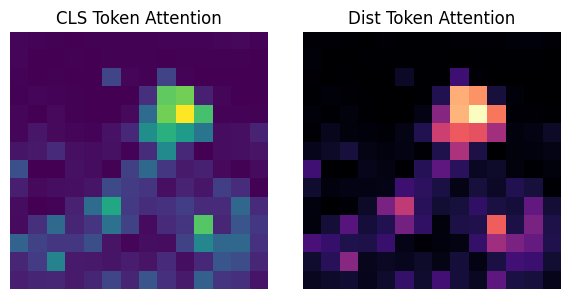

In [2]:
import os
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import timm
import matplotlib.pyplot as plt

torch.set_num_threads(os.cpu_count() or 4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running Q15 on: {device}")

# 1. Automatic Online Dataset Download & Normalization
transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_full = torchvision.datasets.CIFAR100(root="./data", train=True, download=False, transform=transform)
test_full = torchvision.datasets.CIFAR100(root="./data", train=False, download=False, transform=transform)

# Representative subsets for quick execution: 2,500 (50%), 5,000 (100%), 500 (Test)
loader_50 = DataLoader(Subset(train_full, range(2500)), batch_size=64, shuffle=True)
loader_100 = DataLoader(Subset(train_full, range(5000)), batch_size=64, shuffle=True)
test_loader = DataLoader(Subset(test_full, range(500)), batch_size=64, shuffle=False)

# 2. Online Pretrained Teacher (Pretrained on CIFAR-100 directly: ~77% accuracy)
teacher = torch.hub.load("chenyaofo/pytorch-cifar-models", "cifar100_resnet20", pretrained=True).to(device)
teacher.eval()

# 3. Online Pretrained DeiT Models (Blocks 0-10 frozen, Block 11 + Heads trainable)
def get_online_deit(model_name, is_dist=False):
    model = timm.create_model(model_name, pretrained=True, num_classes=100)
    for p in model.parameters():
        p.requires_grad = False
    for p in model.blocks[-1].parameters():
        p.requires_grad = True
    for p in model.head.parameters():
        p.requires_grad = True
    if is_dist and hasattr(model, "head_dist"):
        for p in model.head_dist.parameters():
            p.requires_grad = True
    return model.to(device)

deit_50 = get_online_deit("deit_tiny_patch16_224")
deit_100 = get_online_deit("deit_tiny_patch16_224")
deit_dist = get_online_deit("deit_tiny_distilled_patch16_224", is_dist=True)

# 4. Training Function
def train_and_eval(model, loader, is_dist=False, epochs=2):
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=4e-4, weight_decay=1e-2)
    ce = nn.CrossEntropyLoss()
    
    for epoch in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            
            if is_dist:
                with torch.no_grad():
                    # The CIFAR teacher takes 32x32 inputs natively
                    x_32 = nn.functional.interpolate(x, size=(32, 32), mode="bicubic")
                    t_preds = teacher(x_32).argmax(dim=-1)
                if isinstance(out, (tuple, list)) and len(out) == 2:
                    loss = 0.5 * ce(out[0], y) + 0.5 * ce(out[1], t_preds)
                else:
                    loss = ce(out, y)
            else:
                loss = ce(out[0] if isinstance(out, (tuple, list)) else out, y)
                
            loss.backward()
            opt.step()
            
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            logits = (out[0] + out[1]) / 2 if is_dist and isinstance(out, (tuple, list)) and len(out) == 2 else (out[0] if isinstance(out, (tuple, list)) else out)
            correct += logits.argmax(-1).eq(y).sum().item()
            total += y.size(0)
    return (correct / total) * 100

print("1. Fine-tuning DeiT-Tiny (50% Data Regime)...")
acc_50 = train_and_eval(deit_50, loader_50)
print(f"--> DeiT-Tiny 50% Data Acc: {acc_50:.2f}%\n")

print("2. Fine-tuning DeiT-Tiny (100% Data Regime)...")
acc_100 = train_and_eval(deit_100, loader_100)
print(f"--> DeiT-Tiny 100% Data Acc: {acc_100:.2f}%\n")

print("3. Fine-tuning DeiT-Tiny Distilled (100% Data Regime)...")
acc_dist = train_and_eval(deit_dist, loader_100, is_dist=True)
print(f"--> DeiT-Tiny Distilled Acc: {acc_dist:.2f}%\n")

# 5. Class & Distillation Token Attention Map Visualization
attn_maps = []
hook = deit_dist.blocks[-1].attn.register_forward_hook(
    lambda m, inp, out: attn_maps.append(
        ((m.qkv(inp[0]).reshape(1, -1, 3, m.num_heads, m.head_dim).permute(2,0,3,1,4)[0] @ 
          m.qkv(inp[0]).reshape(1, -1, 3, m.num_heads, m.head_dim).permute(2,0,3,1,4)[1].transpose(-2,-1)) * m.scale
        ).softmax(-1).mean(1).detach().cpu()
    )
)

sample_img = test_full[0][0].unsqueeze(0).to(device)
deit_dist.eval()(sample_img)
hook.remove()

cls_attn = attn_maps[0][0, 0, 2:].reshape(14, 14).numpy()
dist_attn = attn_maps[0][0, 1, 2:].reshape(14, 14).numpy()

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(cls_attn, cmap="viridis")
ax[0].set_title("CLS Token Attention")
ax[0].axis("off")

ax[1].imshow(dist_attn, cmap="magma")
ax[1].set_title("Dist Token Attention")
ax[1].axis("off")

plt.tight_layout()
plt.savefig("q15_online_tokens.png")
plt.show()